# Minimum Width of Uniform AR Support Zonoids

This notebook follows the notation of the thesis section on uniform innovations. The sliding-window vector is taken in past-lag order,

$$
Y_t^{(k)} = (X_t,X_{t-1},\ldots,X_{t-k+1}) \in \mathbb{R}^k,
$$

for the causal \(\mathrm{AR}(p)\) process

$$
X_t = \phi_1 X_{t-1} + \cdots + \phi_p X_{t-p} + Z_t,
\qquad Z_t \in [-a,a].
$$

Writing \(X_t=\sum_{j=0}^{\infty}\psi_j Z_{t-j}\), the support zonoid of \(Y_t^{(k)}\) is generated by

$$
g_j^{(k)}
= a\,(\psi_j,\psi_{j-1},\ldots,\psi_{j-k+1})^T,
\qquad \psi_r=0 \text{ for } r<0.
$$

Thus the finite approximation is

$$
K_{k,n}=\sum_{j=0}^{n}[-1,1]\,g_j^{(k)},
\qquad
K_k=\overline{\sum_{j=0}^{\infty}[-1,1]\,g_j^{(k)}}.
$$

For a direction \(u \in S^{k-1}\),

$$
h_{K_k}(u)=\sum_{j=0}^{\infty}|\langle g_j^{(k)},u\rangle|,
\qquad
w_{K_k}(u)=h_{K_k}(u)+h_{K_k}(-u)
=2\sum_{j=0}^{\infty}|\langle g_j^{(k)},u\rangle|.
$$

The theoretical width profile is

$$
m_k^{\mathrm{theory}}
=\min_{\|u\|_2=1}
\bigl(h_{K_k}(u)+h_{K_k}(-u)\bigr).
$$

At \(k=p+1\), the AR recurrence direction is

$$
q_{\phi}=(1,-\phi_1,\ldots,-\phi_p),
$$

and the normalized direction \(q_{\phi}/\|q_{\phi}\|_2\) has width \(2a/\|q_{\phi}\|_2\).


## Numerical Minimization

The unit sphere \(S^{k-1}\) is parameterized by \(k-1\) hyperspherical angles. For each \(k\), the notebook minimizes

$$
u \longmapsto h_K(u)+h_K(-u)
$$

using SciPy differential evolution followed by bounded Powell polishing. The objective is nonsmooth because of the absolute values in the support-function formula, so a derivative-free global-to-local search is appropriate. For \(k\ge p+1\), the known AR recurrence directions are also evaluated explicitly and included in the minimum.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, minimize
from scipy.spatial import ConvexHull, QhullError

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)


In [2]:
def companion_spectral_radius(phi):
    phi = np.asarray(phi, dtype=float)
    matrix = np.zeros((len(phi), len(phi)))
    matrix[0] = phi
    if len(phi) > 1:
        matrix[1:, :-1] = np.eye(len(phi) - 1)
    return float(np.max(np.abs(np.linalg.eigvals(matrix))))


def automatic_stationary_ar_coefficients(order, first_pacf=0.95, decay=-0.55):
    """Generate stationary AR coefficients from decaying partial autocorrelations."""
    if not isinstance(order, (int, np.integer)) or order < 1:
        raise ValueError("order must be a positive integer")
    if not (abs(first_pacf) < 1 and abs(decay) < 1):
        raise ValueError("first_pacf and decay must have absolute value below one")

    pacf = first_pacf * decay ** np.arange(order)
    phi = np.array([pacf[0]])
    for m in range(2, order + 1):
        old_phi = phi.copy()
        reflection = pacf[m - 1]
        phi = np.empty(m)
        phi[:-1] = old_phi - reflection * old_phi[::-1]
        phi[-1] = reflection
    return phi


def check_stationarity(phi):
    radius = companion_spectral_radius(phi)
    if radius >= 1:
        raise ValueError(f"AR coefficients are not stationary: spectral radius = {radius:.4f}")
    return radius


def ar_recurrence_vector(phi):
    return np.r_[1.0, -np.asarray(phi, dtype=float)]


def ar_recurrence_direction(phi):
    raw = ar_recurrence_vector(phi)
    return raw / np.linalg.norm(raw)


def ar_recurrence_directions(phi, embedding_dimension):
    """All coordinate-shifted thesis-convention AR recurrence directions in R^k."""
    raw = ar_recurrence_vector(phi)
    p_plus_one = len(raw)
    k = int(embedding_dimension)
    if k < p_plus_one:
        return []

    directions = []
    for start in range(k - p_plus_one + 1):
        direction = np.zeros(k)
        direction[start:start + p_plus_one] = raw
        directions.append(direction / np.linalg.norm(direction))
    return directions


In [3]:
def ar_impulse_response(phi, maximum_lag):
    phi = np.asarray(phi, dtype=float)
    order = len(phi)
    psi = np.zeros(maximum_lag + 1)
    psi[0] = 1.0
    for lag in range(1, maximum_lag + 1):
        psi[lag] = sum(
            phi[j - 1] * psi[lag - j]
            for j in range(1, min(order, lag) + 1)
        )
    return psi


def ar_window_zonoid_generators(phi, embedding_dimension, history, half_width=1.0):
    """Columns are g_j^(k)=a(psi_j, psi_{j-1}, ..., psi_{j-k+1}) in thesis convention."""
    k = int(embedding_dimension)
    if k < 1 or history < 0 or half_width <= 0:
        raise ValueError("Require k >= 1, history >= 0, and half_width > 0.")

    psi = ar_impulse_response(phi, history)
    generators = np.zeros((k, history + 1))
    for innovation_lag in range(history + 1):
        for coordinate in range(k):
            response_lag = innovation_lag - coordinate
            if response_lag >= 0:
                generators[coordinate, innovation_lag] = half_width * psi[response_lag]
    return generators[:, np.linalg.norm(generators, axis=0) > 1e-13]


def zonotope_directional_width(generators, u):
    return float(2.0 * np.sum(np.abs(np.asarray(generators).T @ np.asarray(u))))


In [4]:
def angles_to_unit_vector(theta, k):
    """Standard hyperspherical coordinates in R^k."""
    if k == 1:
        return np.ones(1)
    theta = np.asarray(theta)
    u = np.empty(k)
    sine_product = 1.0
    for j in range(k - 1):
        u[j] = sine_product * np.cos(theta[j])
        sine_product *= np.sin(theta[j])
    u[-1] = sine_product
    return u


def _best_candidate_width(generators, candidate_directions):
    if not candidate_directions:
        return None
    best_width = np.inf
    best_direction = None
    for candidate in candidate_directions:
        candidate = np.asarray(candidate, dtype=float)
        norm = np.linalg.norm(candidate)
        if norm <= 0:
            continue
        direction = candidate / norm
        width = zonotope_directional_width(generators, direction)
        if width < best_width:
            best_width = width
            best_direction = direction
    if best_direction is None:
        return None
    return best_width, best_direction


def estimate_minimum_zonotope_width(
    generators, seed=0, de_maxiter=80, de_popsize=8, polish=True,
    candidate_directions=None,
):
    generators = np.asarray(generators, dtype=float)
    k = generators.shape[0]
    if k == 1:
        return {
            "m_hat": zonotope_directional_width(generators, np.ones(1)),
            "u_hat": np.ones(1),
            "global_success": True,
            "local_success": True,
            "source": "exact_1d",
        }

    bounds = [(0.0, np.pi)] * (k - 2) + [(0.0, 2.0 * np.pi)]
    objective = lambda theta: zonotope_directional_width(
        generators, angles_to_unit_vector(theta, k)
    )
    global_result = differential_evolution(
        objective, bounds=bounds, seed=seed, maxiter=de_maxiter,
        popsize=de_popsize, tol=1e-7, updating="immediate", workers=1, polish=False
    )
    best_x, best_fun = global_result.x, global_result.fun
    best_direction = angles_to_unit_vector(best_x, k)
    source = "optimizer"

    local_success = True
    if polish:
        local_result = minimize(
            objective, best_x, method="Powell", bounds=bounds,
            options={"xtol": 1e-9, "ftol": 1e-9, "maxiter": 1_000},
        )
        local_success = bool(local_result.success)
        if local_result.fun < best_fun:
            best_x, best_fun = local_result.x, local_result.fun
            best_direction = angles_to_unit_vector(best_x, k)

    candidate_best = _best_candidate_width(generators, candidate_directions or [])
    if candidate_best is not None and candidate_best[0] < best_fun:
        best_fun, best_direction = candidate_best
        source = "candidate"

    return {
        "m_hat": float(best_fun),
        "u_hat": best_direction,
        "global_success": bool(global_result.success),
        "local_success": local_success,
        "source": source,
    }


## Uniform AR Zonoid Settings

The innovation support is \([-a,a]\), controlled by `innovation_half_width`. The finite-history parameter `history` builds \(K_{k,n}\), while `zonoid_history` uses a longer truncation to approximate the stationary support zonoid \(K_k\).


In [5]:
p = 3
k_max = 7
history = 40
zonoid_history = 250
innovation_half_width = 1.0

# If custom_phi is None, stationary full AR(p) coefficients are generated automatically.
# Example custom_phi for AR(3): np.array([0.6, -0.25, 0.1])
custom_phi = None

optimizer_seed = 17
de_maxiter = 80
de_popsize = 8

phi = np.asarray(custom_phi, dtype=float) if custom_phi is not None else automatic_stationary_ar_coefficients(p)
if len(phi) != p:
    raise ValueError(f"Expected {p} AR coefficients, got {len(phi)}.")
if k_max < 1:
    raise ValueError("k_max must be positive.")
if zonoid_history < history:
    raise ValueError("zonoid_history should be at least as large as history.")
if k_max < p + 1:
    print(f"Warning: k_max={k_max} does not include the recurrence dimension p+1={p+1}.")

radius = check_stationarity(phi)
zonotopes = {
    k: ar_window_zonoid_generators(phi, k, history, innovation_half_width)
    for k in range(1, k_max + 1)
}
zonoid_approximations = {
    k: ar_window_zonoid_generators(phi, k, zonoid_history, innovation_half_width)
    for k in range(1, k_max + 1)
}

print(f"AR order p = {p}; recurrence dimension p+1 = {p + 1}")
print("AR coefficients:", np.round(phi, 5))
print(f"Companion spectral radius = {radius:.4f}")
print(f"Uniform innovation support = [-{innovation_half_width:g}, {innovation_half_width:g}]")
print(f"Finite zonotope history = {history}; zonoid approximation history = {zonoid_history}")
print("Finite-history generator matrices:", {k: G.shape for k, G in zonotopes.items()})
print("Zonoid-approximation generator matrices:", {k: G.shape for k, G in zonoid_approximations.items()})


AR order p = 3; recurrence dimension p+1 = 4
AR coefficients: [ 1.5965 -0.9382  0.2874]
Companion spectral radius = 0.9142
Uniform innovation support = [-1, 1]
Finite zonotope history = 40; zonoid approximation history = 250
Finite-history generator matrices: {1: (1, 41), 2: (2, 41), 3: (3, 41), 4: (4, 41), 5: (5, 41), 6: (6, 41), 7: (7, 41)}
Zonoid-approximation generator matrices: {1: (1, 251), 2: (2, 251), 3: (3, 251), 4: (4, 251), 5: (5, 251), 6: (6, 251), 7: (7, 251)}


## Minimum Width by Scale

For each scale \(k\), we minimize the support-function width

$$
m_k = \min_{\|u\|_2=1} \bigl(h_{K_k}(u)+h_{K_k}(-u)\bigr).
$$

At \(k=p+1\), the table also compares the optimizer direction with the known AR recurrence direction.


In [6]:
results = []
for k in range(1, k_max + 1):
    finite_generators = zonotopes[k]
    zonoid_generators = zonoid_approximations[k]
    candidate_directions = ar_recurrence_directions(phi, k)

    finite_fit = estimate_minimum_zonotope_width(
        finite_generators, seed=optimizer_seed + k,
        de_maxiter=de_maxiter, de_popsize=de_popsize,
        candidate_directions=candidate_directions,
    )
    theoretical_fit = estimate_minimum_zonotope_width(
        zonoid_generators, seed=10_000 + optimizer_seed + k,
        de_maxiter=de_maxiter, de_popsize=de_popsize,
        candidate_directions=candidate_directions,
    )

    row = {
        "k": k,
        "finite_width": finite_fit["m_hat"],
        "theoretical_width": theoretical_fit["m_hat"],
        "theoretical_width_over_a": theoretical_fit["m_hat"] / max(innovation_half_width, np.finfo(float).eps),
        "u_hat": theoretical_fit["u_hat"],
        "finite_source": finite_fit["source"],
        "theory_source": theoretical_fit["source"],
        "finite_DE_converged": finite_fit["global_success"],
        "theory_DE_converged": theoretical_fit["global_success"],
        "theory_Powell_converged": theoretical_fit["local_success"],
        "alignment_with_AR_direction": np.nan,
        "width_in_AR_direction": np.nan,
        "closed_form_AR_width": np.nan,
    }
    if k >= p + 1:
        recurrence_widths = [
            zonotope_directional_width(zonoid_generators, direction)
            for direction in candidate_directions
        ]
        row["width_in_AR_direction"] = min(recurrence_widths)
        row["closed_form_AR_width"] = 2.0 * innovation_half_width / np.linalg.norm(ar_recurrence_vector(phi))
    if k == p + 1:
        u_ar = ar_recurrence_direction(phi)
        row["alignment_with_AR_direction"] = abs(theoretical_fit["u_hat"] @ u_ar)
    results.append(row)

result_table = pd.DataFrame(results)
display_columns = [
    "k", "finite_width", "theoretical_width", "theoretical_width_over_a",
    "finite_source", "theory_source",
    "alignment_with_AR_direction", "width_in_AR_direction", "closed_form_AR_width",
]
print(result_table[display_columns].round(6).to_string(index=False))


 k  finite_width  theoretical_width  theoretical_width_over_a finite_source theory_source  alignment_with_AR_direction  width_in_AR_direction  closed_form_AR_width
 1     35.933718          36.867326                 36.867326      exact_1d      exact_1d                          NaN                    NaN                   NaN
 2      3.190177           3.190187                  3.190187     optimizer     optimizer                          NaN                    NaN                   NaN
 3      1.692525           1.692532                  1.692532     optimizer     optimizer                          NaN                    NaN                   NaN
 4      0.941594           0.941594                  0.941594     candidate     candidate                          1.0               0.941594              0.941594
 5      0.941594           0.941594                  0.941594     candidate     candidate                          NaN               0.941594              0.941594
 6      0.941594

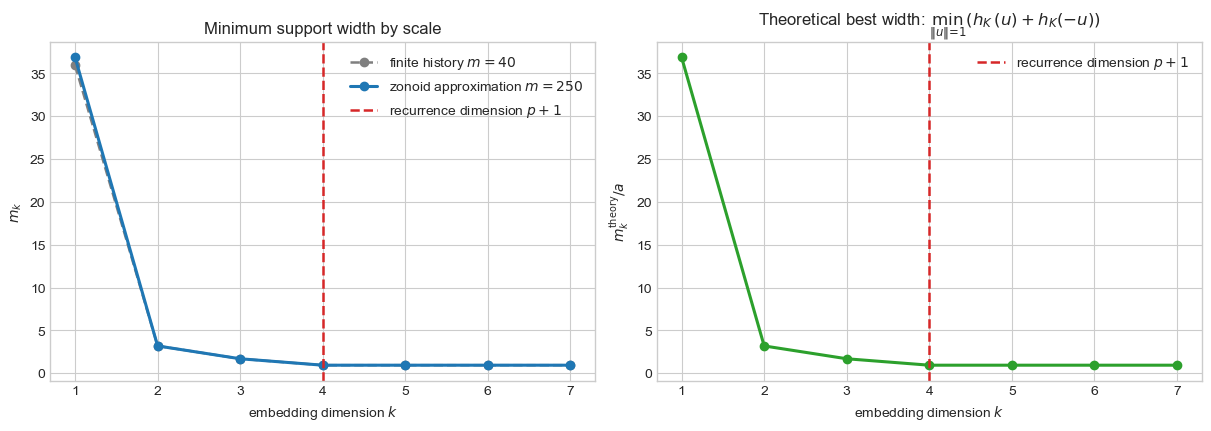

|<u_hat, u_AR>| at k=p+1: 1.000000
Width in AR direction: 0.941594
Closed-form AR-direction width: 0.941594


In [7]:
ks = result_table["k"].to_numpy()
finite_width = result_table["finite_width"].to_numpy()
theoretical_width = result_table["theoretical_width"].to_numpy()
theoretical_relative = result_table["theoretical_width_over_a"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

axes[0].plot(ks, finite_width, "o--", lw=1.8, color="tab:gray", label=fr"finite history $m={history}$")
axes[0].plot(ks, theoretical_width, "o-", lw=2.2, color="tab:blue", label=fr"zonoid approximation $m={zonoid_history}$")
axes[0].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=r"recurrence dimension $p+1$")
axes[0].set(xticks=ks, xlabel=r"embedding dimension $k$", ylabel=r"$m_k$")
axes[0].set_title(r"Minimum support width by scale")
axes[0].legend()

axes[1].plot(ks, theoretical_relative, "o-", lw=2.2, color="tab:green")
axes[1].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=r"recurrence dimension $p+1$")
axes[1].set(xticks=ks, xlabel=r"embedding dimension $k$", ylabel=r"$m_k^{\mathrm{theory}}/a$")
axes[1].set_title(r"Theoretical best width: $\min_{\|u\|=1}(h_K(u)+h_K(-u))$")
axes[1].legend()

plt.show()

if p + 1 <= k_max:
    target_row = result_table.loc[result_table["k"] == p + 1].iloc[0]
    print(f"|<u_hat, u_AR>| at k=p+1: {target_row['alignment_with_AR_direction']:.6f}")
    print(f"Width in AR direction: {target_row['width_in_AR_direction']:.6f}")
    print(f"Closed-form AR-direction width: {target_row['closed_form_AR_width']:.6f}")


## First Plateau Scale Selection

For the uniform AR support zonoid, the theoretical minimum-width sequence

$$
m_k = \min_{\|u\|_2=1} w_{K_k}(u)
$$

stops decreasing once the AR recurrence direction is available. Hence the order signal is the first plateau scale:

$$
\widehat{k}
= \min\{k : m_k,m_{k+1},\ldots \text{ show no further decrease}\}.
$$

Equivalently, with

$$
\Delta_k = \log m_k - \log m_{k+1},
\qquad
F_k = \sum_{j=k}^{k_{\max}-1}\Delta_j,
$$

we choose the first scale with negligible future improvement. The smooth score used below is

$$
s_k = \frac{\exp(-F_k/\tau)}{k},
$$

so that all plateau scales score highly, but the first plateau scale wins because of the factor \(1/k\).


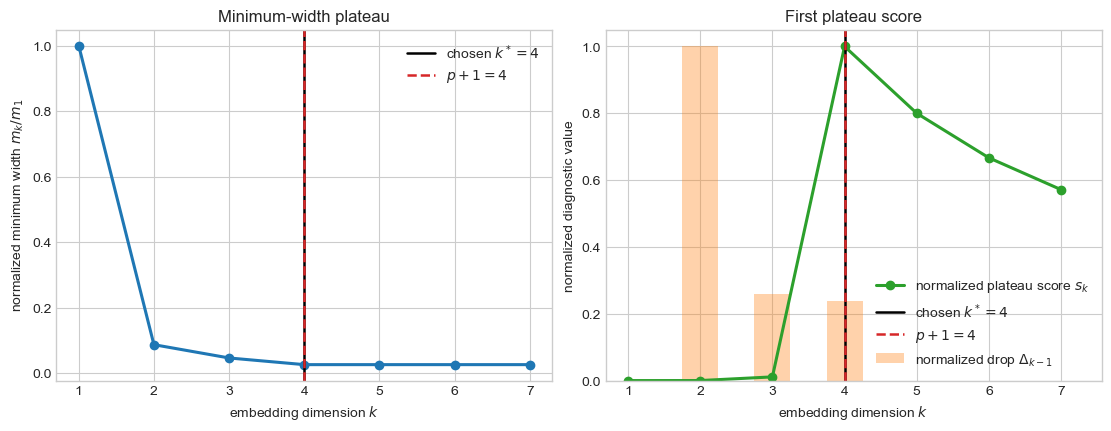

First plateau choice: k* = 4
Estimated AR order: p_hat = k* - 1 = 3


In [8]:
def first_plateau_statistics(width_sequence, temperature_fraction=0.05):
    widths = np.asarray(width_sequence, dtype=float)
    k_count = len(widths)
    log_width = np.log(np.maximum(widths, np.finfo(float).tiny))
    drops = np.maximum(0.0, log_width[:-1] - log_width[1:])
    drop_scale = max(float(np.max(drops)), 1e-12)

    future_improvement = np.zeros(k_count)
    for index in range(k_count - 1):
        future_improvement[index] = np.sum(drops[index:])

    temperature = temperature_fraction * drop_scale
    score = np.exp(-future_improvement / temperature) / np.arange(1, k_count + 1)
    selected_k = int(np.argmax(score) + 1)
    return {
        "drops": drops,
        "future_improvement": future_improvement,
        "score": score,
        "selected_k": selected_k,
    }


plateau_stats = first_plateau_statistics(theoretical_width)
selected_k = plateau_stats["selected_k"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

axes[0].plot(ks, theoretical_width / theoretical_width[0], "o-", lw=2.2, color="tab:blue")
axes[0].axvline(selected_k, color="black", lw=1.8, label=fr"chosen $k^*={selected_k}$")
axes[0].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=fr"$p+1={p+1}$")
axes[0].set(
    xticks=ks,
    xlabel=r"embedding dimension $k$",
    ylabel=r"normalized minimum width $m_k/m_1$",
    title=r"Minimum-width plateau",
)
axes[0].legend()

score = plateau_stats["score"] / np.max(plateau_stats["score"])
drop_positions = ks[1:]
drops = plateau_stats["drops"]
normalized_drops = drops / max(np.max(drops), np.finfo(float).eps)
axes[1].bar(drop_positions, normalized_drops, width=0.5, color="tab:orange", alpha=0.35, label=r"normalized drop $\Delta_{k-1}$")
axes[1].plot(ks, score, "o-", lw=2.2, color="tab:green", label=r"normalized plateau score $s_k$")
axes[1].axvline(selected_k, color="black", lw=1.8, label=fr"chosen $k^*={selected_k}$")
axes[1].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=fr"$p+1={p+1}$")
axes[1].set(
    xticks=ks,
    xlabel=r"embedding dimension $k$",
    ylabel=r"normalized diagnostic value",
    title=r"First plateau score",
)
axes[1].legend()
plt.show()

print(f"First plateau choice: k* = {selected_k}")
print(f"Estimated AR order: p_hat = k* - 1 = {selected_k - 1}")


## Empirical Trimmed-Width First Plateau Check

The trimmed version replaces the raw empirical range by a central projection width. Given observations \(X_1,\ldots,X_n\), define

$$
Y_t^{(k)}=(X_t,X_{t-1},\ldots,X_{t-k+1})\in\mathbb{R}^k.
$$

For \(u\in S^{k-1}\), let \(Q_\alpha^{(k,u)}\) denote the empirical \(\alpha\)-quantile of the projected sample \(\langle u,Y_t^{(k)}\rangle\). The trimmed empirical width is

$$
\widehat w_{k,\alpha}(u)
=
Q_{1-\alpha}^{(k,u)}-Q_{\alpha}^{(k,u)},
$$

and

$$
\widehat m_{k,\alpha}
=
\min_{u\in S^{k-1}} \widehat w_{k,\alpha}(u).
$$

The same first-plateau score is then applied to

$$
\widehat m_{1,\alpha},\ldots,\widehat m_{k_{\max},\alpha}.
$$

Here \(\alpha=0.025\) is used by default. This is less sensitive to individual extremes than max-minus-min, but it also changes the population object: for fixed \(\alpha>0\), the estimator targets a central width, not the exact support width. Therefore the clean population plateau at \(p+1\) need not survive perfectly.


,p,target_k,alpha,success_rate,selected_counts
0,1,2,0.025,0.54,"[0, 54, 23, 11, 12]"
1,2,3,0.025,0.16,"[0, 7, 16, 3, 35, 39]"
2,3,4,0.025,0.05,"[0, 1, 3, 5, 4, 8, 79]"
3,4,5,0.025,0.04,"[0, 0, 1, 2, 4, 2, 21, 70]"
4,5,6,0.025,0.03,"[0, 0, 1, 0, 0, 3, 4, 11, 81]"


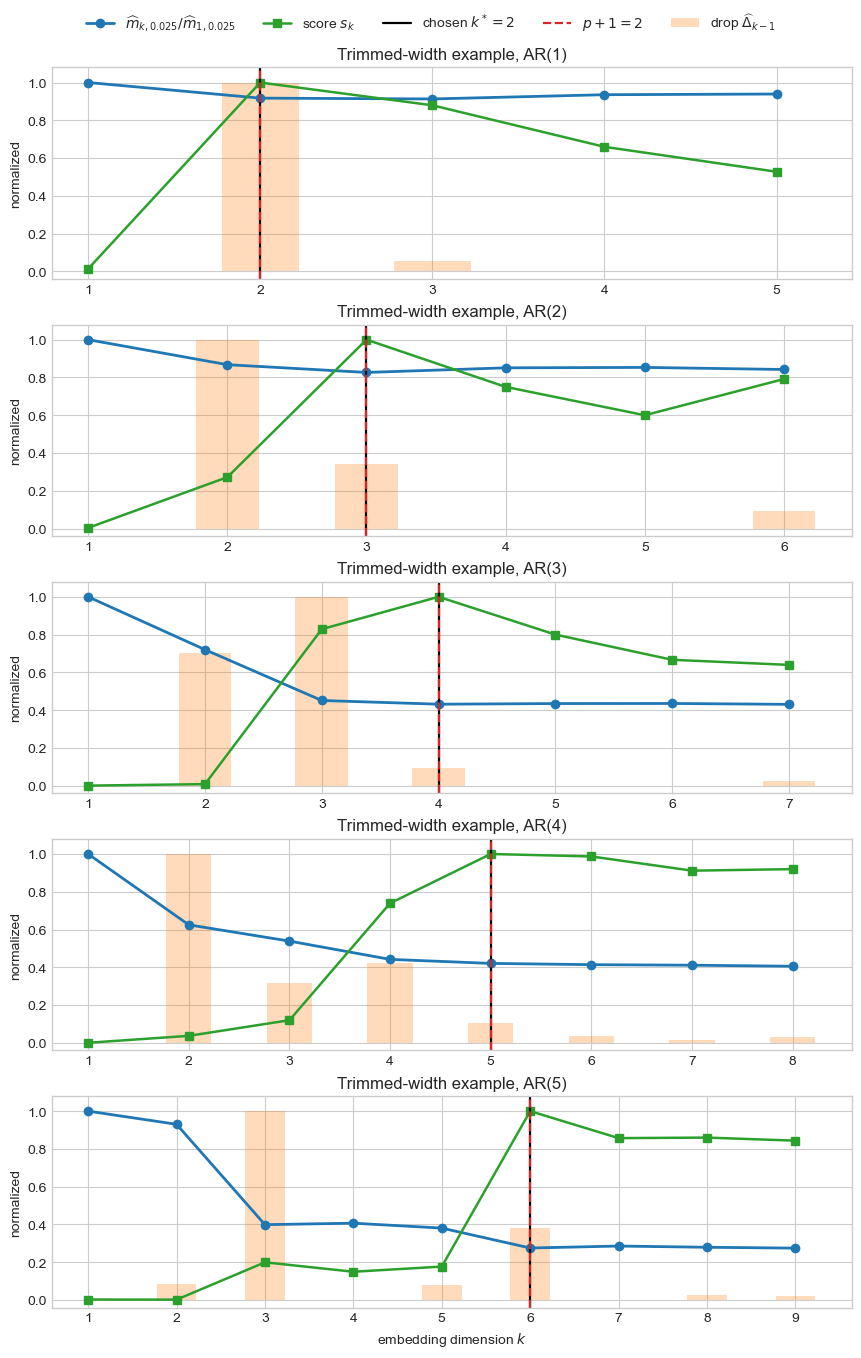

In [9]:
trim_alpha = 0.025


def random_stationary_ar_coefficients(order, rng, max_abs_pacf=0.85, min_last_abs_pacf=0.08):
    pacf = rng.uniform(-max_abs_pacf, max_abs_pacf, size=order)
    if abs(pacf[-1]) < min_last_abs_pacf:
        pacf[-1] = np.sign(pacf[-1] if pacf[-1] != 0 else 1.0) * min_last_abs_pacf

    phi = np.array([pacf[0]])
    for m in range(2, order + 1):
        old_phi = phi.copy()
        reflection = pacf[m - 1]
        phi = np.empty(m)
        phi[:-1] = old_phi - reflection * old_phi[::-1]
        phi[-1] = reflection
    return phi


def simulate_uniform_ar(phi, sample_size, burn_in=500, half_width=1.0, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    phi = np.asarray(phi, dtype=float)
    order = len(phi)
    total = sample_size + burn_in + order
    innovations = rng.uniform(-half_width, half_width, size=total)
    series = np.zeros(total)

    for t in range(order, total):
        past = series[t - np.arange(1, order + 1)]
        series[t] = np.dot(phi, past) + innovations[t]

    return series[burn_in + order:]


def delay_vectors(series, embedding_dimension):
    series = np.asarray(series, dtype=float)
    k = int(embedding_dimension)
    n = len(series)
    if k < 1 or n < k:
        raise ValueError("Require 1 <= embedding_dimension <= len(series).")
    return np.column_stack([series[k - 1 - lag:n - lag] for lag in range(k)])


def empirical_trimmed_widths_from_projections(projections, alpha):
    projections = np.asarray(projections, dtype=float)
    if projections.ndim == 1:
        projections = projections[:, None]
    sample_size = projections.shape[0]
    lower_index = int(np.floor(alpha * (sample_size - 1)))
    upper_index = int(np.ceil((1.0 - alpha) * (sample_size - 1)))
    partitioned = np.partition(projections, (lower_index, upper_index), axis=0)
    return partitioned[upper_index] - partitioned[lower_index]


def empirical_trimmed_width(delay_matrix, direction, alpha=trim_alpha):
    projections = np.asarray(delay_matrix) @ np.asarray(direction)
    return float(empirical_trimmed_widths_from_projections(projections, alpha)[0])


def estimate_minimum_empirical_trimmed_width(
    delay_matrix,
    alpha=trim_alpha,
    seed=0,
    n_random_directions=192,
    n_local_directions=96,
    use_global_optimizer=False,
    de_maxiter=20,
    de_popsize=4,
    polish=False,
):
    """Approximate min_{||u||=1} trimmed projection width.

    The default search is estimation-free and fast: it evaluates the smallest
    empirical-variance direction, random sphere directions, and local
    perturbations of the smallest-variance direction. The optional global
    optimizer is slower and usually not needed for the diagnostic plots.
    """
    delay_matrix = np.asarray(delay_matrix, dtype=float)
    k = delay_matrix.shape[1]
    if k == 1:
        return {
            "m_hat": empirical_trimmed_width(delay_matrix, np.ones(1), alpha=alpha),
            "u_hat": np.ones(1),
            "source": "exact_1d",
        }

    rng = np.random.default_rng(seed)
    centered = delay_matrix - delay_matrix.mean(axis=0, keepdims=True)
    _, _, right_singular_vectors = np.linalg.svd(centered, full_matrices=False)
    pca_thin_direction = right_singular_vectors[-1]

    candidate_blocks = [pca_thin_direction.reshape(1, -1)]

    random_directions = rng.normal(size=(n_random_directions, k))
    random_directions /= np.linalg.norm(random_directions, axis=1, keepdims=True)
    candidate_blocks.append(random_directions)

    local_blocks = []
    directions_per_scale = max(1, n_local_directions // 4)
    for noise_scale in [0.03, 0.08, 0.16, 0.32]:
        local = pca_thin_direction + noise_scale * rng.normal(size=(directions_per_scale, k))
        local /= np.linalg.norm(local, axis=1, keepdims=True)
        local_blocks.append(local)
    candidate_blocks.append(np.vstack(local_blocks))

    candidates = np.vstack(candidate_blocks)
    candidate_widths = empirical_trimmed_widths_from_projections(delay_matrix @ candidates.T, alpha)
    best_index = int(np.argmin(candidate_widths))
    best_width = float(candidate_widths[best_index])
    best_direction = candidates[best_index]
    source = "pca_random_search"

    if use_global_optimizer:
        bounds = [(0.0, np.pi)] * (k - 2) + [(0.0, 2.0 * np.pi)]
        objective = lambda theta: empirical_trimmed_width(delay_matrix, angles_to_unit_vector(theta, k), alpha=alpha)

        global_result = differential_evolution(
            objective,
            bounds=bounds,
            seed=seed,
            maxiter=de_maxiter,
            popsize=de_popsize,
            tol=1e-5,
            updating="immediate",
            workers=1,
            polish=False,
        )
        if global_result.fun < best_width:
            best_width = float(global_result.fun)
            best_direction = angles_to_unit_vector(global_result.x, k)
            source = "differential_evolution"

        if polish:
            local_result = minimize(
                objective,
                global_result.x,
                method="Powell",
                bounds=bounds,
                options={"xtol": 1e-7, "ftol": 1e-7, "maxiter": 500},
            )
            if local_result.fun < best_width:
                best_width = float(local_result.fun)
                best_direction = angles_to_unit_vector(local_result.x, k)
                source = "powell_polish"

    return {"m_hat": best_width, "u_hat": best_direction, "source": source}


def empirical_trimmed_width_sequence(series, k_max_local, alpha=trim_alpha, seed=0, **estimator_kwargs):
    widths = np.zeros(k_max_local)
    sources = []
    for k in range(1, k_max_local + 1):
        cloud = delay_vectors(series, k)
        result = estimate_minimum_empirical_trimmed_width(cloud, alpha=alpha, seed=seed + k, **estimator_kwargs)
        widths[k - 1] = result["m_hat"]
        sources.append(result["source"])
    return widths, sources


def run_trimmed_first_plateau_monte_carlo(
    orders=range(1, 6),
    repetitions=100,
    sample_size=3_000,
    extra_scales=3,
    alpha=trim_alpha,
    plateau_temperature_fraction=0.20,
    seed=20260712,
    estimator_kwargs=None,
):
    rng = np.random.default_rng(seed)
    estimator_kwargs = {} if estimator_kwargs is None else dict(estimator_kwargs)
    rows = []
    examples = {}

    for order in orders:
        target_k = order + 1
        k_max_local = target_k + extra_scales
        selected_values = []
        first_example = None
        first_correct_example = None

        for rep in range(repetitions):
            phi_rep = random_stationary_ar_coefficients(order, rng)
            series = simulate_uniform_ar(phi_rep, sample_size=sample_size, rng=rng)
            widths, sources = empirical_trimmed_width_sequence(
                series,
                k_max_local=k_max_local,
                alpha=alpha,
                seed=10_000 * order + rep * 100,
                **estimator_kwargs,
            )
            stats = first_plateau_statistics(
                widths,
                temperature_fraction=plateau_temperature_fraction,
            )
            selected_k = stats["selected_k"]
            selected_values.append(selected_k)

            example = {
                "phi": phi_rep,
                "widths": widths,
                "stats": stats,
                "target_k": target_k,
                "selected_k": selected_k,
                "k_values": np.arange(1, k_max_local + 1),
                "sources": sources,
            }
            if first_example is None:
                first_example = example
            if first_correct_example is None and selected_k == target_k:
                first_correct_example = example

        selected_values = np.asarray(selected_values)
        counts = np.bincount(selected_values, minlength=k_max_local + 1)[1:]
        rows.append({
            "p": order,
            "target_k": target_k,
            "alpha": alpha,
            "success_rate": np.mean(selected_values == target_k),
            "selected_counts": counts.tolist(),
        })
        examples[order] = first_correct_example if first_correct_example is not None else first_example

    return pd.DataFrame(rows), examples


trimmed_plateau_df, trimmed_plateau_examples = run_trimmed_first_plateau_monte_carlo()
display(trimmed_plateau_df)

fig, axes = plt.subplots(5, 1, figsize=(8.5, 13.5), sharex=False, constrained_layout=True)
for axis, order in zip(axes, range(1, 6)):
    example = trimmed_plateau_examples[order]
    k_values = example["k_values"]
    widths = example["widths"]
    stats = example["stats"]
    selected_k = example["selected_k"]
    target_k = example["target_k"]

    normalized_width = widths / widths[0]
    normalized_score = stats["score"] / np.max(stats["score"])
    normalized_drops = stats["drops"] / max(np.max(stats["drops"]), np.finfo(float).eps)

    axis.plot(k_values, normalized_width, "o-", lw=2.0, color="tab:blue", label=fr"$\widehat m_{{k,{trim_alpha}}}/\widehat m_{{1,{trim_alpha}}}$")
    axis.bar(k_values[1:], normalized_drops, width=0.45, color="tab:orange", alpha=0.28, label=r"drop $\widehat\Delta_{k-1}$")
    axis.plot(k_values, normalized_score, "s-", lw=1.8, color="tab:green", label=r"score $s_k$")
    axis.axvline(selected_k, color="black", lw=1.6, label=fr"chosen $k^*={selected_k}$")
    axis.axvline(target_k, color="tab:red", ls="--", lw=1.6, label=fr"$p+1={target_k}$")
    axis.set(
        xticks=k_values,
        ylim=(-0.04, 1.08),
        ylabel="normalized",
        title=fr"Trimmed-width example, AR({order})",
    )

axes[-1].set_xlabel(r"embedding dimension $k$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=5)
plt.show()


The trimmed-width experiment is intentionally included as a robustness check. It is more stable against individual extremes than raw max-minus-min, but it no longer estimates the exact support width when \(\alpha\) is fixed. In this experiment, that change destroys the clean first-plateau signal: later embeddings often have narrower central projection distributions even after the support-width plateau has already appeared.

For \(\alpha=0.025\), sample size \(n=3000\), and 100 simulations per order, the observed success rates were:

| \(p\) | target \(p+1\) | success rate | selected-count vector |
|---:|---:|---:|---|
| 1 | 2 | 0.54 | [0, 54, 23, 11, 12] |
| 2 | 3 | 0.16 | [0, 7, 16, 3, 35, 39] |
| 3 | 4 | 0.05 | [0, 1, 3, 5, 4, 8, 79] |
| 4 | 5 | 0.04 | [0, 0, 1, 2, 4, 2, 21, 70] |
| 5 | 6 | 0.03 | [0, 0, 1, 0, 0, 3, 4, 11, 81] |

So trimming solves the single-extreme sensitivity, but it changes the target geometry too much for this particular plateau criterion. The support-width plateau is a boundary statement; a fixed central quantile width is a distributional central-spread statement.


## Difference-Body Slab Width Benchmark

The minimum empirical range width can also be computed from the difference body. If

$$
K=\operatorname{conv}\{Y_t^{(k)}\},
\qquad
D=K-K,
$$

then

$$
\max_t \langle u,Y_t^{(k)}\rangle-
\min_t \langle u,Y_t^{(k)}\rangle
=
h_D(u).
$$

Therefore

$$
\widehat m_k
=
\min_{\|u\|=1}h_D(u)
=
r_0(D),
$$

where \(r_0(D)\) is the radius of the largest Euclidean ball centered at the origin and contained in \(D\). If

$$
D=\bigcap_r\{z:a_r^\top z\le b_r\},
$$

then

$$
\widehat m_k
=
\min_r \frac{b_r}{\|a_r\|_2}.
$$

The exact construction uses all pairwise differences \(x_i-x_j\), so it is expensive for large delay clouds. The implementation below uses it exactly for small clouds and otherwise first compresses the cloud to points that are extreme in many directions. This gives a useful computational-geometry benchmark for the slab-width estimator.


The difference-body method is a more geometric way to compute the empirical max-minus-min width. It can certify the minimum when the full difference body is feasible. For realistic delay clouds, however, the exact body \(K-K\) is too large, so the notebook uses a directional-extreme compression before forming pairwise differences.

In the AR(3) example above, this benchmark selected \(k^*=7\) although the theoretical target is \(p+1=4\). The table also shows why the exact computational-geometry route becomes hard quickly: even after compression, the number of facets of the approximate difference body grew from 1,108 at \(k=4\) to 758,542 at \(k=7\).

So this construction is useful as a small-dimensional benchmark and as a principled way to compute slab width, but it mainly improves the optimization side of the problem. It does not remove the statistical issue that finite empirical convex hulls approximate support bodies slowly in higher dimension.


## Prediction-Error First Plateau Check

The prediction-error version uses the AR recurrence idea directly but without knowing the true coefficients. For scale \(k\), fit the linear prediction model

$$
X_t = \beta_0 + \beta_1X_{t-1}+\cdots+\beta_{k-1}X_{t-k+1}+\varepsilon_t^{(k)}
$$

by least squares and define

$$
\widehat m_k^{\mathrm{pred}}
=
\frac{1}{N_k}\sum_t \left(\widehat\varepsilon_t^{(k)}\right)^2.
$$

For an \(\mathrm{AR}(p)\) process, the correct predictor first becomes available at \(k=p+1\). Hence the residual variance should decrease until \(k=p+1\) and then plateau near the innovation variance. The same first-plateau rule can therefore be applied to

$$
\widehat m_1^{\mathrm{pred}},\ldots,\widehat m_{k_{\max}}^{\mathrm{pred}}.
$$

This is not a support-zonotope width, but it is a stable empirical analogue of the recurrence-direction idea.


,p,target_k,success_rate,selected_counts
0,1,2,0.75,"[0, 75, 3, 5, 17]"
1,2,3,0.86,"[0, 5, 86, 1, 3, 5]"
2,3,4,0.96,"[0, 1, 1, 96, 1, 0, 1]"
3,4,5,0.94,"[0, 0, 0, 6, 94, 0, 0, 0]"
4,5,6,0.92,"[0, 0, 0, 1, 7, 92, 0, 0, 0]"


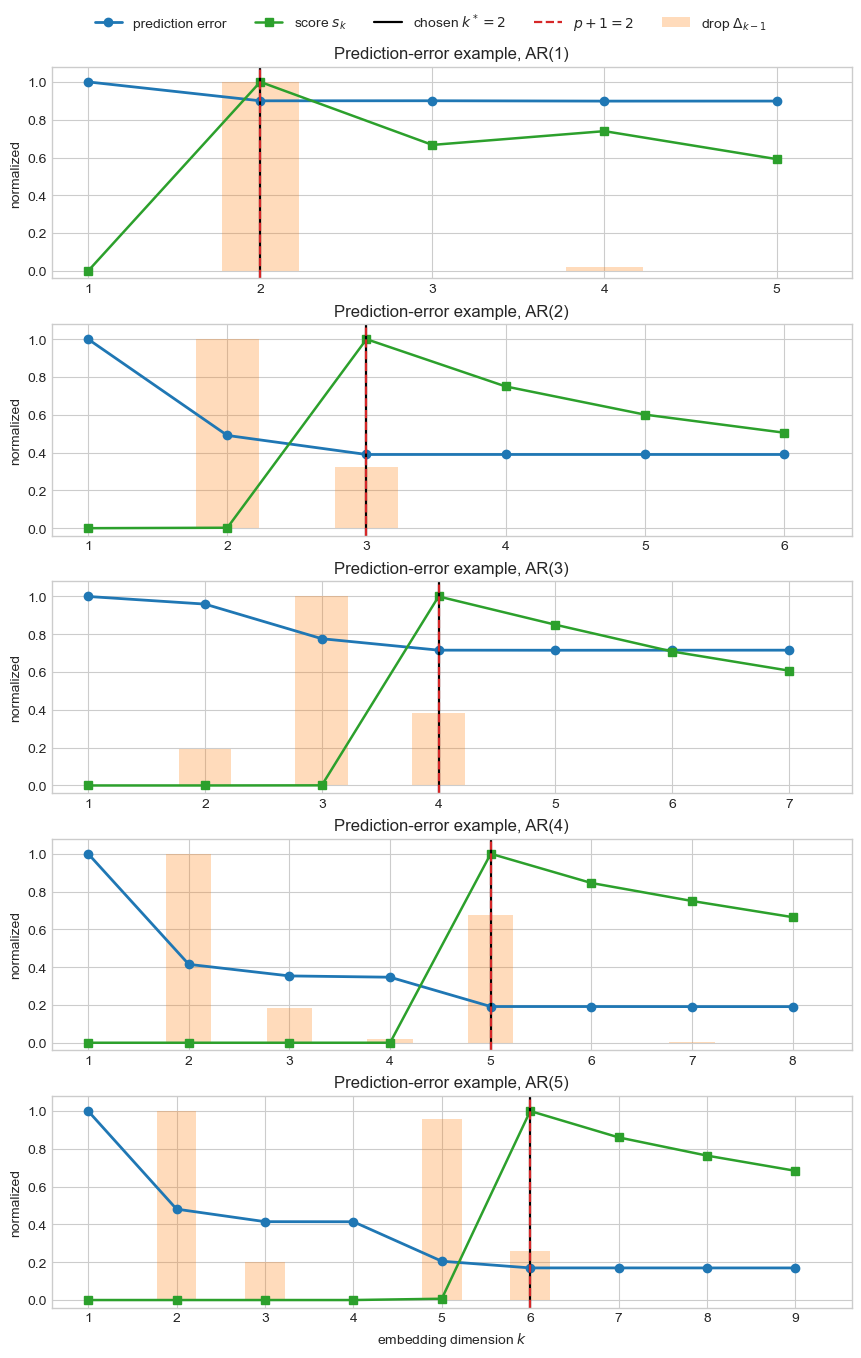

In [11]:
def prediction_error_sequence(series, k_max_local):
    series = np.asarray(series, dtype=float)
    values = np.zeros(k_max_local)

    for k in range(1, k_max_local + 1):
        n_lags = k - 1
        response = series[n_lags:]

        if n_lags == 0:
            residuals = response - np.mean(response)
        else:
            design = np.column_stack([
                series[n_lags - lag:len(series) - lag]
                for lag in range(1, n_lags + 1)
            ])
            design = np.column_stack([np.ones(len(response)), design])
            coefficients, *_ = np.linalg.lstsq(design, response, rcond=None)
            residuals = response - design @ coefficients

        values[k - 1] = np.mean(residuals ** 2)

    return values


def run_prediction_error_monte_carlo(
    orders=range(1, 6),
    repetitions=100,
    sample_size=3_000,
    extra_scales=3,
    plateau_temperature_fraction=0.05,
    seed=20260712,
):
    rng = np.random.default_rng(seed)
    rows = []
    examples = {}

    for order in orders:
        target_k = order + 1
        k_max_local = target_k + extra_scales
        selected_values = []
        first_example = None
        first_correct_example = None

        for rep in range(repetitions):
            phi_rep = random_stationary_ar_coefficients(order, rng)
            series = simulate_uniform_ar(phi_rep, sample_size=sample_size, rng=rng)
            prediction_errors = prediction_error_sequence(series, k_max_local)
            stats = first_plateau_statistics(
                prediction_errors,
                temperature_fraction=plateau_temperature_fraction,
            )
            selected_k = stats["selected_k"]
            selected_values.append(selected_k)

            example = {
                "phi": phi_rep,
                "prediction_errors": prediction_errors,
                "stats": stats,
                "target_k": target_k,
                "selected_k": selected_k,
                "k_values": np.arange(1, k_max_local + 1),
            }
            if first_example is None:
                first_example = example
            if first_correct_example is None and selected_k == target_k:
                first_correct_example = example

        selected_values = np.asarray(selected_values)
        counts = np.bincount(selected_values, minlength=k_max_local + 1)[1:]
        rows.append({
            "p": order,
            "target_k": target_k,
            "success_rate": np.mean(selected_values == target_k),
            "selected_counts": counts.tolist(),
        })
        examples[order] = first_correct_example if first_correct_example is not None else first_example

    return pd.DataFrame(rows), examples


prediction_error_df, prediction_error_examples = run_prediction_error_monte_carlo()
display(prediction_error_df)

fig, axes = plt.subplots(5, 1, figsize=(8.5, 13.5), sharex=False, constrained_layout=True)
for axis, order in zip(axes, range(1, 6)):
    example = prediction_error_examples[order]
    k_values = example["k_values"]
    errors = example["prediction_errors"]
    stats = example["stats"]
    selected_k = example["selected_k"]
    target_k = example["target_k"]

    normalized_errors = errors / errors[0]
    normalized_score = stats["score"] / np.max(stats["score"])
    normalized_drops = stats["drops"] / max(np.max(stats["drops"]), np.finfo(float).eps)

    axis.plot(k_values, normalized_errors, "o-", lw=2.0, color="tab:blue", label=r"prediction error")
    axis.bar(k_values[1:], normalized_drops, width=0.45, color="tab:orange", alpha=0.28, label=r"drop $\Delta_{k-1}$")
    axis.plot(k_values, normalized_score, "s-", lw=1.8, color="tab:green", label=r"score $s_k$")
    axis.axvline(selected_k, color="black", lw=1.6, label=fr"chosen $k^*={selected_k}$")
    axis.axvline(target_k, color="tab:red", ls="--", lw=1.6, label=fr"$p+1={target_k}$")
    axis.set(
        xticks=k_values,
        ylim=(-0.04, 1.08),
        ylabel="normalized",
        title=fr"Prediction-error example, AR({order})",
    )

axes[-1].set_xlabel(r"embedding dimension $k$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=5)
plt.show()


The prediction-error plateau is much more stable than the empirical support-width variants. It does not estimate the support-zonotope width, but it directly estimates when the AR recurrence has become available for linear prediction.

For sample size \(n=3000\) and 100 simulations per order, the observed success rates were:

| \(p\) | target \(p+1\) | success rate | selected-count vector |
|---:|---:|---:|---|
| 1 | 2 | 0.75 | [0, 75, 3, 5, 17] |
| 2 | 3 | 0.86 | [0, 5, 86, 1, 3, 5] |
| 3 | 4 | 0.96 | [0, 1, 1, 96, 1, 0, 1] |
| 4 | 5 | 0.94 | [0, 0, 0, 6, 94, 0, 0, 0] |
| 5 | 6 | 0.92 | [0, 0, 0, 1, 7, 92, 0, 0, 0] |

This is the best empirical behavior among the methods tried so far. The price is conceptual: the criterion is no longer a support-width criterion, but a prediction-error criterion tied to the same AR recurrence direction.


## Common-Thinness Support-Function Kernel

The common-thinness idea compares not just one chosen minimizing direction, but the relative thinness profile

$$
r_k(u)=\frac{m_k}{w_{K_k}(\rho_k(u))},
\qquad
\rho_k(u)=\frac{P_ku}{\|P_ku\|}.
$$

Thus \(r_k(u)\le 1\), and values close to one mean that the projected ambient direction is nearly a minimum-width direction for scale \(k\). The hard common-thinness similarity is approximated by

$$
\Sigma_{k\ell}^{\mathrm{common}}
\approx
\max_r \min\{r_k(U_r),r_\ell(U_r)\}.
$$

For the population AR zonotope, all scales \(k\ge p+1\) share the recurrence direction, so the lower-right block beginning at \(p+1\) should be close to one. The useful diagnostic is therefore not a Perron peak, but the first high-similarity tail block.


For the displayed population AR(3) example, the common-thinness construction should be read as a tail-block detector. The hard-common matrix gives the expected lower-right block of ones from scales \(4,5,6,7\), and the first-tail-block score selects

$$
k^*=4=p+1.
$$

This is encouraging, but the matrix also illustrates why a Perron-vector peak is not the right readout: early low-dimensional scales, especially \(k=1\), can have high compatibility with many later scales because their minimizing-direction set is trivial or broad. The useful signal is the first coherent tail block, not the largest eigenvector entry.

In pilot simulations, this worked well for higher orders but could start one step early for \(p=2\). So the idea is mathematically attractive as a population block-structure diagnostic, but it is not yet as empirically robust as the prediction-error plateau.


## Model-Assisted Estimated Zonotope Widths

The empirical convex hull estimator tries to recover the whole support body from delay vectors. The following experiment keeps the zonoid geometry, but estimates the impulse response first. A high-order AR model is fitted without inserting the true order \(p\). In the default version below, the high-order AR fit is sparse and selected by a BIC-type Lasso criterion.

From the estimated coefficients one computes

$$
\widehat\psi_0=1,
\qquad
\widehat\psi_j=\sum_{i=1}^{\min(q,j)}\widehat\phi_i\widehat\psi_{j-i}.
$$

For each embedding dimension \(k\), the estimated zonotope generators are

$$
\widehat g_j^{(k)}=\widehat a\,(\widehat\psi_j,\widehat\psi_{j-1},\ldots,\widehat\psi_{j-k+1})^T,
\qquad \widehat\psi_r=0 \text{ for } r<0.
$$

The width minimization is then applied to the estimated zonotope:

$$
\widetilde m_k
=
\min_{\|u\|=1}
2\sum_j |\langle \widehat g_j^{(k)},u\rangle|.
$$

The minimizer used here is an iteratively reweighted quadratic surrogate for the nonsmooth \(\ell_1\)-type objective. It is much faster than repeated global differential evolution and is sufficient for the Monte Carlo diagnostic.


In [ ]:
from sklearn.linear_model import LassoLarsIC


def fit_sparse_ar_coefficients(series, order, threshold=1e-4):
    """Fit a high-order AR model and keep a sparse effective lag structure.

    The true order is not supplied. The BIC criterion chooses the Lasso penalty.
    Trailing coefficients below `threshold` are removed before the impulse response
    is computed, so the resulting filter has an estimated effective order.
    """
    series = np.asarray(series, dtype=float)
    order = int(order)
    response = series[order:]
    raw_design = np.column_stack([
        series[order - lag:len(series) - lag]
        for lag in range(1, order + 1)
    ])
    scale = np.maximum(raw_design.std(axis=0), 1e-12)
    design = (raw_design - raw_design.mean(axis=0, keepdims=True)) / scale
    response_centered = response - response.mean()

    model = LassoLarsIC(criterion="bic", fit_intercept=False).fit(design, response_centered)
    coefficients = model.coef_ / scale
    coefficients[np.abs(coefficients) < threshold] = 0.0

    nonzero = np.flatnonzero(np.abs(coefficients) > 0)
    if len(nonzero) == 0:
        coefficients = np.array([0.0])
    else:
        coefficients = coefficients[:nonzero[-1] + 1]

    residuals = response_centered - design @ model.coef_
    return coefficients, residuals


def stable_estimated_impulse_response(phi_hat, maximum_lag, stability_radius=0.985):
    phi_hat = np.asarray(phi_hat, dtype=float).copy()
    radius = companion_spectral_radius(phi_hat)
    if radius >= stability_radius:
        phi_hat *= stability_radius / radius
    return ar_impulse_response(phi_hat, maximum_lag), phi_hat, radius


def estimated_window_zonotope_generators(psi_hat, embedding_dimension, history, half_width=1.0):
    k = int(embedding_dimension)
    history = int(history)
    generators = np.zeros((k, history + 1))
    for innovation_lag in range(history + 1):
        for coordinate in range(min(k, innovation_lag + 1)):
            response_lag = innovation_lag - coordinate
            generators[coordinate, innovation_lag] = half_width * psi_hat[response_lag]
    return generators[:, np.linalg.norm(generators, axis=0) > 1e-13]


def minimum_zonotope_width_irls(
    generators,
    seed=0,
    n_random_starts=12,
    n_iterations=25,
    smoothing=1e-5,
):
    """Approximate min_{||u||=1} 2 sum_j |<g_j,u>| by IRLS."""
    generators = np.asarray(generators, dtype=float)
    k = generators.shape[0]
    if k == 1:
        return {
            "m_hat": zonotope_directional_width(generators, np.ones(1)),
            "u_hat": np.ones(1),
        }

    rng = np.random.default_rng(seed)
    starts = []
    starts.extend(np.eye(k))
    starts.extend(-np.eye(k))
    try:
        _, _, right_singular_vectors = np.linalg.svd(generators.T, full_matrices=False)
        starts.extend(right_singular_vectors[-min(k, len(right_singular_vectors)):])
    except np.linalg.LinAlgError:
        pass

    random_starts = rng.normal(size=(n_random_starts, k))
    random_starts /= np.linalg.norm(random_starts, axis=1, keepdims=True)
    starts.extend(random_starts)

    matrix = generators.T
    best_width = np.inf
    best_direction = None

    for start in starts:
        direction = np.asarray(start, dtype=float)
        direction /= np.linalg.norm(direction)

        for _ in range(n_iterations):
            projected = matrix @ direction
            weights = 1.0 / np.sqrt(projected ** 2 + smoothing ** 2)
            quadratic = (matrix.T * weights) @ matrix
            eigenvalues, eigenvectors = np.linalg.eigh(quadratic)
            new_direction = eigenvectors[:, np.argmin(eigenvalues)]
            if np.dot(new_direction, direction) < 0:
                new_direction = -new_direction
            if np.linalg.norm(new_direction - direction) < 1e-7:
                direction = new_direction
                break
            direction = new_direction

        value = zonotope_directional_width(generators, direction)
        if value < best_width:
            best_width = value
            best_direction = direction.copy()

    return {"m_hat": float(best_width), "u_hat": best_direction}


def estimated_impulse_zonotope_width_sequence(
    series,
    k_max_local,
    ar_fit_order=None,
    impulse_history=120,
    residual_quantile=0.995,
    optimizer_seed=0,
):
    if ar_fit_order is None:
        ar_fit_order = k_max_local + 5

    phi_hat_raw, residuals = fit_sparse_ar_coefficients(series, ar_fit_order)
    psi_hat, phi_hat, raw_radius = stable_estimated_impulse_response(
        phi_hat_raw,
        maximum_lag=impulse_history,
    )
    a_hat = float(np.quantile(np.abs(residuals), residual_quantile))

    widths = []
    directions = []
    for k in range(1, k_max_local + 1):
        generators = estimated_window_zonotope_generators(
            psi_hat,
            embedding_dimension=k,
            history=impulse_history,
            half_width=a_hat,
        )
        fit = minimum_zonotope_width_irls(
            generators,
            seed=optimizer_seed + k,
        )
        widths.append(fit["m_hat"])
        directions.append(fit["u_hat"])

    return {
        "widths": np.asarray(widths),
        "directions": directions,
        "phi_hat": phi_hat,
        "raw_radius": raw_radius,
        "estimated_ar_order": max(0, len(phi_hat)),
        "a_hat": a_hat,
        "fit_order": ar_fit_order,
    }


def run_estimated_impulse_zonotope_monte_carlo(
    orders=range(1, 7),
    repetitions=50,
    sample_size=3_000,
    extra_scales=4,
    ar_fit_extra_lags=5,
    impulse_history=120,
    plateau_temperature_fraction=0.05,
    seed=20260712,
):
    rng = np.random.default_rng(seed)
    rows = []
    examples = {}

    for order in orders:
        target_k = order + 1
        k_max_local = target_k + extra_scales
        selected_values = []
        estimated_orders = []
        first_example = None
        first_correct_example = None

        for rep in range(repetitions):
            phi_rep = random_stationary_ar_coefficients(order, rng)
            series = simulate_uniform_ar(phi_rep, sample_size=sample_size, rng=rng)
            result = estimated_impulse_zonotope_width_sequence(
                series,
                k_max_local=k_max_local,
                ar_fit_order=k_max_local + ar_fit_extra_lags,
                impulse_history=impulse_history,
                optimizer_seed=10_000 * order + rep,
            )
            stats = first_plateau_statistics(
                result["widths"],
                temperature_fraction=plateau_temperature_fraction,
            )
            selected_k = stats["selected_k"]
            selected_values.append(selected_k)
            estimated_orders.append(result["estimated_ar_order"])

            example = {
                "phi": phi_rep,
                "widths": result["widths"],
                "stats": stats,
                "target_k": target_k,
                "selected_k": selected_k,
                "k_values": np.arange(1, k_max_local + 1),
                "estimated_ar_order": result["estimated_ar_order"],
                "a_hat": result["a_hat"],
                "fit_order": result["fit_order"],
            }
            if first_example is None:
                first_example = example
            if first_correct_example is None and selected_k == target_k:
                first_correct_example = example

        selected_values = np.asarray(selected_values)
        estimated_orders = np.asarray(estimated_orders)
        counts = np.bincount(selected_values, minlength=k_max_local + 1)[1:]
        rows.append({
            "p": order,
            "target_k": target_k,
            "success_rate": np.mean(selected_values == target_k),
            "counts": counts,
            "median_sparse_ar_order": np.median(estimated_orders),
            "mean_selected_k": np.mean(selected_values),
        })
        examples[order] = first_correct_example or first_example

    return pd.DataFrame(rows), examples


estimated_impulse_zonotope_summary, estimated_impulse_zonotope_examples = run_estimated_impulse_zonotope_monte_carlo()

print("Sparse estimated impulse-zonotope minimum-width experiment")
for row in estimated_impulse_zonotope_summary.itertuples(index=False):
    print(
        f"p={row.p}, target k={row.target_k}, "
        f"success={row.success_rate:.2f}, "
        f"median sparse AR order={row.median_sparse_ar_order:.1f}, "
        f"counts={row.counts.tolist()}"
    )

fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.8), constrained_layout=True)
for ax, row in zip(axes.flat, estimated_impulse_zonotope_summary.itertuples(index=False)):
    k_values = np.arange(1, len(row.counts) + 1)
    colors = ["tab:blue" if k != row.target_k else "tab:orange" for k in k_values]
    ax.bar(k_values, row.counts, color=colors, alpha=0.9)
    ax.axvline(row.target_k, color="black", ls="--", lw=1.2)
    ax.set(
        title=fr"$p={row.p}$, target $k={row.target_k}$",
        xticks=k_values,
        xlabel=r"chosen scale $k^*$",
        ylabel="count",
        ylim=(0, 50),
    )
fig.suptitle(r"Sparse estimated impulse-zonotope first-plateau selections", y=1.02)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.8), constrained_layout=True)
for ax, order in zip(axes.flat, sorted(estimated_impulse_zonotope_examples)):
    example = estimated_impulse_zonotope_examples[order]
    k_values = example["k_values"]
    normalized_widths = example["widths"] / example["widths"][0]
    normalized_score = example["stats"]["score"] / np.max(example["stats"]["score"])
    ax.plot(k_values, normalized_widths, "o-", lw=2.0, label=r"$\widetilde m_k/\widetilde m_1$")
    ax.plot(k_values, normalized_score, "s--", lw=1.5, label=r"plateau score")
    ax.axvline(example["target_k"], color="black", ls="--", lw=1.2, label=r"target")
    ax.axvline(example["selected_k"], color="tab:orange", lw=1.6, label=r"chosen")
    ax.set(
        title=fr"$p={order}$, chosen $k^*={example['selected_k']}$, sparse order $={example['estimated_ar_order']}$",
        xticks=k_values,
        xlabel=r"scale $k$",
        ylabel="normalized value",
    )
axes.flat[0].legend(fontsize=8)
fig.suptitle(r"Example sparse estimated impulse-zonotope width curves", y=1.02)
plt.show()

display(estimated_impulse_zonotope_summary)
